# House Price Prediction Using Machine Learning
**A Case Study of the Melbourne Housing Market**

Dataset: Melbouurne Housing Market

Dataset Source: OpenML

## 1. Business Understanding

### 1.1 Business Problem

Residential real estate prices are influenced by a variety of factors, including location, property size, and proximity to the city center. Understanding how these factors relate to propetry value helps buyers, sellers and real estate professionals make more informed decisions.

This project explores the application of machine learning techniques to predict residential real estate prices in Melbourne, Australia, based on available data on the housing stock.

### 1.2 Project Objectives

Examine dataset and identify significant property features.

Analyze missing value, data quality issues, and relationships between variables.

Develop a linear regression model to serve as a baseline solution.

Develop a random forest regressor model and compare its performance against the baseline model.

Evaluate prediction accuracy and discuss the strengths and limitations of the models used.

### 1.3 Research Question

How accurately can residential real estate prices be predicted using property characteristics and does random forest regression method outperform linear regression?

### 1.4 Modelling Approach

Linear Regression: a baseline model that estimates house prices using linear relationships between input features and the target variable.

Random Forest Regressor: an ensemble learning method that combines multiple decision trees and can capture nonlinear relationships.

The target cariable will be Price.

### 1.5 Success Criteria

The project will be considered successful if:
- both models are capable of generating predictions for new real estate property records.
- a comparison has been made to determine which model yields the best results on the selected test data.

Model performance will be evaluated against a baselinee and interpreted within the context of this specific dataset.

### 1.6 Limitations

The dataset represents historical property transactions and may not reflect current market conditions.

Missing values, incomplete propetry infomation and changes in the housing market may affect prediction accuracy.

## 2. Data Understanding
### 2.1 Dataset Loading

The dataset was obtained from OpenML and converted from ARFF to CSV format. The conversion process is documented in phase 3

In [2]:
import pandas as pd
df = pd.read_csv('/content/melbourne_housing.csv')
print ("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (13580, 21)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


### 2.2 Dataset Structure
The dataset contains 13,580 records and 21 columns, including Price.

The attributes describe property characteristics, locationsale information. Missing values are also visible in some attributes, like BuildingArea and YearBuilt.

The next step is to examine list of variables, their data types and the number of non-null values.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 non-null  float64
 18  Longti

### 2.3 Missing Values Analysis

The dataset contains 13 numerical variables and 8 variables stored as objects.

Identifiedmissing data in 4 columns: BuildingArea, YearBuilt, CouncilArea and Car.

The largest proportion of missing values occurs in BuildingArea and YearBuilt. This is an important data quality issue because removing all incomplete records could substantially reduce dataset.


In [4]:
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum()/len(df)*100).round(2)
})
missing_values[missing_values['Missing Count']>0].sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Count,Missing Percentage
BuildingArea,6450,47.50
YearBuilt,5375,39.58
CouncilArea,1369,10.08
Car,62,0.46


### 2.4 Descriptive Statistics

The analysis includes calculating the mean, standart deviation, minimum, maximum and quartiles for each numerical features.

Particular attention is paid to targetg variable - Price - as well as to property characteristics such as number of rooms, number of bathrooms, distance, building area.

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rooms,13580.0,2.937997e+00,0.955748,1.00000,2.000000,3.000000,3.000000e+00,1.000000e+01
Price,13580.0,1.075684e+06,639310.724296,85000.00000,650000.000000,903000.000000,1.330000e+06,9.000000e+06
Distance,13580.0,1.013778e+01,5.868725,0.00000,6.100000,9.200000,1.300000e+01,4.810000e+01
Postcode,13580.0,3.105302e+03,90.676964,3000.00000,3044.000000,3084.000000,3.148000e+03,3.977000e+03
Bedroom2,13580.0,2.914728e+00,0.965921,0.00000,2.000000,3.000000,3.000000e+00,2.000000e+01
Bathroom,13580.0,1.534242e+00,0.691712,0.00000,1.000000,1.000000,2.000000e+00,8.000000e+00
Car,13518.0,1.610075e+00,0.962634,0.00000,1.000000,2.000000,2.000000e+00,1.000000e+01
Landsize,13580.0,5.584161e+02,3990.669241,0.00000,177.000000,440.000000,6.510000e+02,4.330140e+05
BuildingArea,7130.0,1.519676e+02,541.014538,0.00000,93.000000,126.000000,1.740000e+02,4.451500e+04
YearBuilt,8205.0,1.964684e+03,37.273762,1196.00000,1940.000000,1970.000000,1.999000e+03,2.018000e+03


Statistics reveal a spread in residential property prices.

Mean price is approximately 1.076 million dollars, while the median - 903,000.

The median numbers of rooms is 3 and median distance to the city center is 9.2 km.

Several variables contain potentially anomalous values. The land size reaches 433,014 m², whereas the median value is 440 m². The maximum building area is 44,515 m² compared to median value of 126m².

Minimum recorded value for the year built is 1196, which may indicate issues with data quality.



### 2.5 Price Distribution


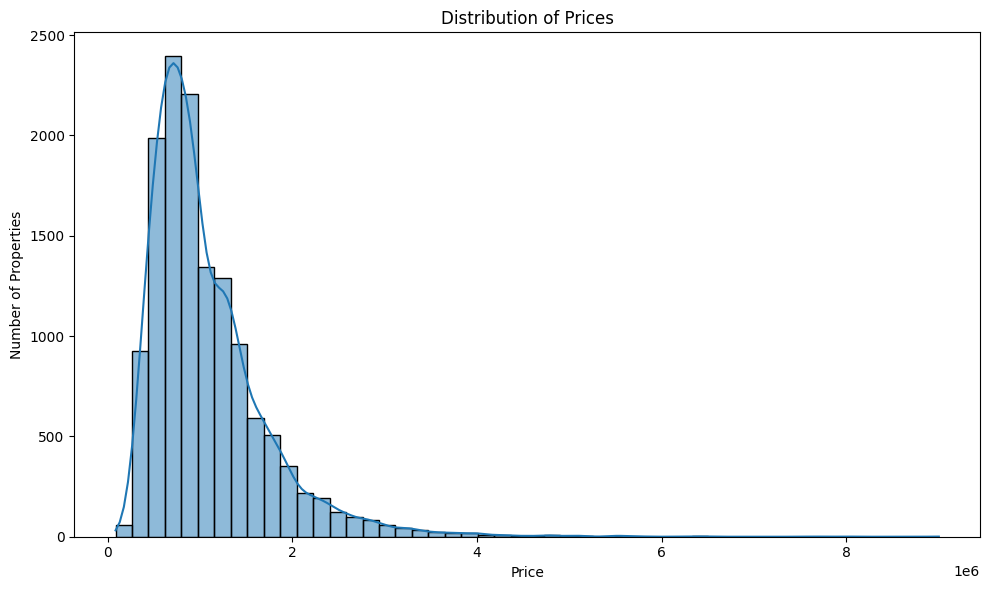

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.histplot(df['Price'], bins=50, kde=True)
plt.title('Distribution of Prices')
plt.xlabel('Price')
plt.ylabel('Number of Properties')
plt.tight_layout()
plt.show()

**Interpretation of Price Distribution**

The most properties concentrated in the lower and middle price range. A long right tail indicates that a relatively small number of properties have substantially higher price.

### 2.6 Relationship Between Rooms and Price

A barplot is used to compare price distributions across different room counts and to identify varibility and potential outliers within each group.

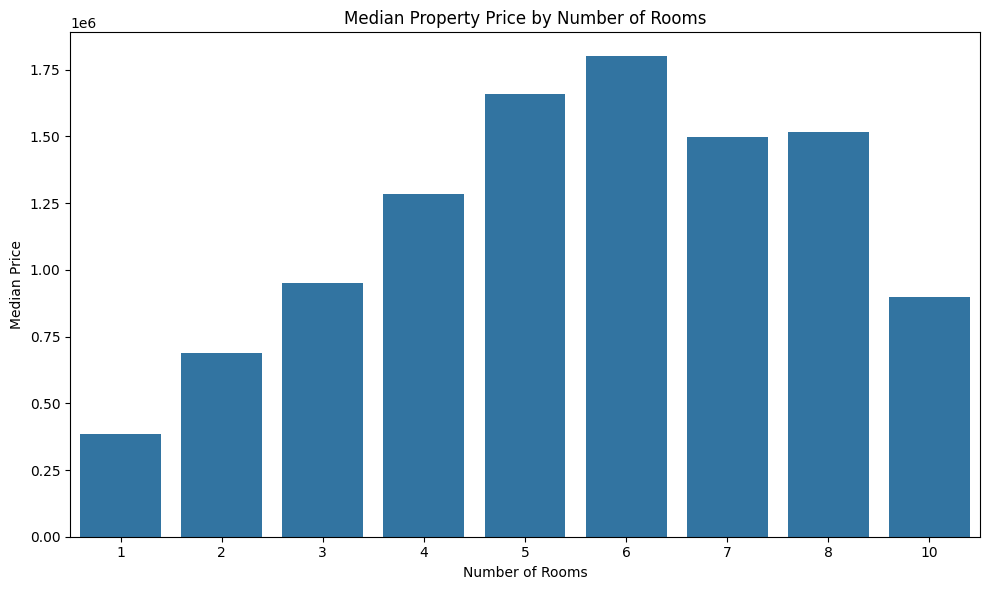

In [7]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=df,
    x='Rooms',
    y='Price',
    estimator='median',
    errorbar=None
)
plt.title('Median Property Price by Number of Rooms')
plt.xlabel('Number of Rooms')
plt.ylabel('Median Price')
plt.tight_layout()
plt.show()

The bar chart shows a general increase in median property prices as the number of rooms increases, particularly for properties with 1 to 6 rooms.The relationship is not stricly linear. Properties with 7, 8, and 10 rooms have lower median prices those with six rooms.

This variation may be influenced by differences in property location, type and the number of observations within each room category.

Overall, the results suggest that the rooms may be useful predictor of property prices.

### 2.7 Check the number of objects

In [8]:
room_counts=df['Rooms'].value_counts().sort_index()
display(room_counts)

,count
Rooms,
1,681
2,3648
3,5881
4,2688
5,596
6,67
7,10
8,8
10,1


The majority of real estate properties have between 2 and 4 rooms. The most common category consists of properties with 3 rooms (5,881).

The median price for properties with 10 rooms is based on a single observation and cannot be considered representative.

### 2.8 Relationship between Distance and Price

A scatterplot is used to investigate whether properties located father from the city center tend to have lower prices.

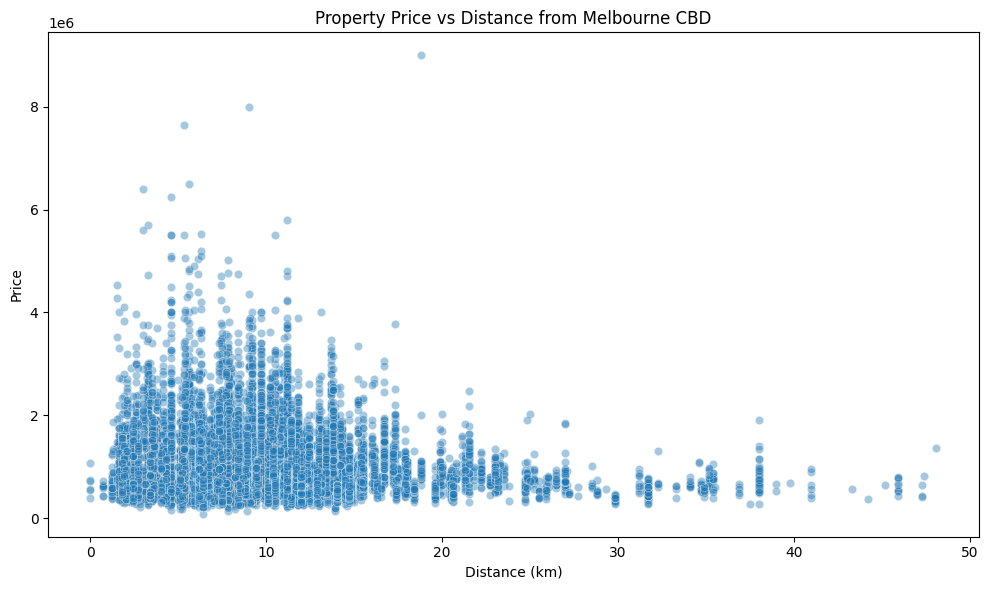

In [9]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x='Distance',
    y='Price',
    alpha=0.4
)
plt.title('Property Price vs Distance from Melbourne CBD')
plt.xlabel('Distance (km)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

Higher-priced properties are more frequently observed within approximately 5-15km of the city centre. As distance increases, the upper range of property prices generally decreases.

Several high-priced outliers are also visible, including a property valued at approximately 9 million around 18 km from Central Business District.

### 2.9 Correlation Analysis

Pearson correlation coefficiets are calculated to investigate linear relationships between numerical property characteristics and the target variable, Price.

In [10]:
numeric_df= df.select_dtypes(include='number')
price_correlations = (
    numeric_df.corr()['Price']
    .sort_values(ascending=False)
)
display(price_correlations)

,Price
Price,1.000000
Rooms,0.496634
Bedroom2,0.475951
Bathroom,0.467038
Car,0.238979
Longtitude,0.203656
Postcode,0.107867
BuildingArea,0.090981
Landsize,0.037507
Propertycount,-0.042153


**Interpretation of Correlation Analysis**

The correlation analysis indicates that Rooms (r=0.497), Bedroom2 (r=0.476), and Bathroom (r=0.467) have the strongest positive linear relationships with property prices among the numerical variables.

Distance has a weak negative correlation with Price (r=-0.163), suggesting that properties father from centre tend to have somewhat lower prices, although the relationship is not strong.

YearBuilt shows a moderate negative correlation (r=-0.324). However, this result should be interpreted cautiously because variable contains many missing values and potentially invalid observations.

Landsize (r=0.038) and BuildingArea (r=0.091) show weak linear relationships with price. This does not necessarily mean these features are unimportant, as nonlinear relationships and outliers may affect the results.

Overall, the analysis suggests that property characteristics and location may contribute to price prediction.

### 2.10 Data Quality Assesment

Before preparing dataset for modelling, additional dataquality checks are performed to identify duplicate records, potentially invalid values.

Particular attention is given to variables where descriptive statistics revealed unusual observations, including YearBuilt, BuildingArea, Landsize.

In [11]:
print("Duplicate rows:", df.duplicated().sum())
print("YearBuilt before 1800:", (df['YearBuilt']<1800).sum())
print("BuildingArea equal to zero:", (df['BuildingArea'] == 0).sum())
print("Landsize equal to zero:", (df['Landsize'] == 0).sum())
print("Bathroom equal to zero:", (df['Bathroom'] ==0).sum())

Duplicate rows: 0
YearBuilt before 1800: 1
BuildingArea equal to zero: 17
Landsize equal to zero: 1939
Bathroom equal to zero: 34


In [12]:
# Investigate zero land size by property type
pd.crosstab(
    df['Type'],
    df['Landsize'] == 0,
    rownames=['Property Type'],
    colnames=['Landsize is Zero']
)

Landsize is Zero,False,True
Property Type,,
h,9278,171
t,975,139
u,1388,1629


**Investigation of Zero Land Size Values**

The cross-tabulation shows that zero values in Landsize are strongly associated with property type.

Among properties classified as units (u) 1,629 out of 3,017 observations have a recorded land size of zero.

In comparison, zero land size is recorded for approximatly 12.5% of townhouses (t) and only 1.8% of houses (h).

The pattern suggests that zero land size may reflect differences in how land area is recorded for different property types, rather than necessarily indicating invalid data.

## 3. Data Preparation
### 3.1 Dataset Format Conversion (ARFF to CSV)

The original dataset was downloaded from OpenML in ARFF format.
The dataset was converted to CSV format using Python and the liac-arff and pandas libraries.

References: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html

In [14]:
%pip install liac-arff

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for liac-arff: filename=liac_arff-2.5.0-py3-none-any.whl size=11772 sha256=aa1b908f3cacb94c5c70a2d1b7aaedc9d48e3311331b4cf2b5f2df56db5b647d
  Stored in directory: /root/.cache/pip/wheels/93/f3/5b/658a9bddee916a5f4b84bdc1a4e0fabd22fb17947c2c9542e6
Successfully built liac-arff


In [15]:
from ast import Attribute
import arff
import pandas as pd

with open('/content/dataset_', 'r', encoding='utf-8') as file:
    dataset = arff.load(file)

columns = [attribute[0] for attribute in dataset['attributes']]
df = pd.DataFrame(dataset['data'], columns=columns)

df.to_csv('/content/melbourne_housing.csv', index=False)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (13580, 21)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


### 3.2 Data Cleaning

Cleaning decisions will be based on the results of the exploratory analysis. In particular, zero values in Landsize will not be automatically removed because they are common among properties classified as units.

Missing values and potentially invalid observations will be investigated before deciding how to handle them.

In [18]:
df_raw = pd.read_csv('/content/melbourne_housing.csv')
df_clean = df_raw.copy()
print("Original dataset shape:", df_raw.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (13580, 21)
Working dataset shape: (13580, 21)


### 3.3 Investigation of Potentially Invalid Values

The descriptive statistics revealed potentially unusual values in YearBuilt, BuildingArea, Bathroom.

It is necessary to determine whether these values are the results of data entry errors, missing information, or are in fact, valid observations.

In [19]:
print("Properties built before 1800:")
display(
    df_clean.loc[
        df_clean['YearBuilt']<1800,
        ['Suburb', 'Type', 'Price', 'YearBuilt']
    ]
)

print("Properties with zero building area:")
display(
    df_clean.loc[
        df_clean['BuildingArea'] == 0,
        ['Suburb', 'Type', 'BuildingArea']
    ].head(10)
)

print("Properties with zero bathrooms:")
display(
    df_clean.loc[
        df_clean['Bathroom'] == 0,
        ['Suburb', 'Type', 'Rooms', 'Bathroom']
    ].head(10)
)

Properties built before 1800:


,Suburb,Type,Price,YearBuilt
9968,Mount Waverley,h,1200000.0,1196.0


Properties with zero building area:


,Suburb,Type,BuildingArea
4344,North Melbourne,t,0.0
12226,Balwyn North,h,0.0
12249,Bundoora,h,0.0
12395,Roxburgh Park,h,0.0
12412,Thornbury,t,0.0
13040,Prahran,h,0.0
13207,Huntingdale,h,0.0
13348,Balwyn North,h,0.0
13370,Brighton East,h,0.0
13380,Bundoora,h,0.0


Properties with zero bathrooms:


,Suburb,Type,Rooms,Bathroom
139,Alphington,h,3,0.0
281,Armadale,u,2,0.0
505,Balaclava,u,2,0.0
584,Balwyn,h,2,0.0
913,Bentleigh East,h,3,0.0
1063,Brighton,h,3,0.0
1070,Brighton,t,3,0.0
1593,Camberwell,h,4,0.0
2253,Elsternwick,u,2,0.0
2777,Glen Iris,h,2,0.0


### 3.4 Handing Potentially Invalid Values

The TearBuilt value of 1196 was considered implausible and replaced with NaN.
Zero values in BuildingArea, Bathroom were treated as potentially missing measurements and replaced with NaN. This decision assumes that these zero values do not represent valid measurements for the intended prediction task.

In [20]:
import numpy as np
df_clean = df_raw.copy()
df_clean.loc[df_clean['YearBuilt']<1800, 'YearBuilt']=np.nan
df_clean.loc[df_clean['BuildingArea'] == 0, 'BuildingArea']=np.nan
df_clean.loc[df_clean['Bathroom'] == 0, 'Bathroom']=np.nan

comparison=pd.DataFrame({
    'Before cleaning': df_raw.isna().sum(),
    'After Cleaning': df_clean.isna().sum()
})

display(comparison[comparison['After Cleaning']>0])
print("Original shape:", df_raw.shape)
print("Cleaned shape:", df_clean.shape)

,Before cleaning,After Cleaning
Bathroom,0,34
Car,62,62
BuildingArea,6450,6467
YearBuilt,5375,5376
CouncilArea,1369,1369


Original shape: (13580, 21)
Cleaned shape: (13580, 21)


### 3.5 Data Preparation Log

The initial cleaning stage converted selected potentially invalid values to missing values without removing any property records.

| Issue | Action | Records Affected | Rationale |
|---|---|---|---|
| YearBuilt < 1800 | Replaced with NaN | 1 | Implausible construction year |
| BuildingArea = 0 | Replaced with NaN | 17 | Potentially missing measurement |
| Bathroom = 0 | Replaced with NaN | 34 | Potentially invalid bathroom count |
| Landsize = 0 | Retained | 1939 | Common among units |

### 3.6 Feature Selection

The target variable is Price. Candidate predictors include property size, room counts, location, property type, and other available characteristics.

In [21]:
feature_summary = pd.DataFrame({
    'Data Type': df_clean.dtypes,
    'Unique Values': df_clean.nunique(),
    'Missing Values': df_clean.isna().sum()
})
display(feature_summary)

,Data Type,Unique Values,Missing Values
Suburb,object,314,0
Address,object,13378,0
Rooms,int64,9,0
Type,object,3,0
Price,float64,2204,0
Method,object,5,0
SellerG,object,268,0
Date,object,58,0
Distance,float64,202,0
Postcode,float64,198,0


Based on the exploratory analysis and feature summary, 12 predictor variables were selected for the initial modelling experiment.

Numerical features: Rooms, Bedroom2, Bathroom, Car, Distance, Landsize, BuildingArea, YearBuilt, Lattitude, Longtitude.

Categorical features: Type, Regionname.

The Address variable was excluded because it contains nearly unique values for individual properties. High-cardinality categorical variables such as Suburn, SellerG were excluded from initial experiment to reduce preprocessing complexity.

In [22]:
numerical_features = [
    'Rooms', 'Bedroom2', 'Bathroom', 'Car',
    'Distance', 'Landsize', 'BuildingArea',
    'YearBuilt', 'Lattitude', 'Longtitude'
]
categorical_feature = [
    'Type', 'Regionname'
]
X=df_clean[numerical_features + categorical_feature]
y=df_clean['Price']
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Selected features:", X.columns.tolist())

Features shape: (13580, 12)
Target shape: (13580,)
Selected features: ['Rooms', 'Bedroom2', 'Bathroom', 'Car', 'Distance', 'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude', 'Type', 'Regionname']


### 3.7 Train/Test Split

The dataset was divided into training and testing subsets using 80/20 split.

A fixed random state of 42 was used to make the split reproducible.

Missing-value imputation and categorical encoding will be fitted only on the training data through a preprocessing pipeline. This approach helps prevent data leakage from the test set.

Both Linear Regression and Random Forest Regressor will use the same trainig and testing subsets.

In [23]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state=42
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (10864, 12)
X_test: (2716, 12)
y_train: (10864,)
y_test: (2716,)
